## Module 3: Computational Drug Discovery Project

**Team:** Sullivan Company, Team ___ *(add team member names)*

## Project Goal:

This project was carried out from the perspective of a Quantitative Systems Pharmacology team at the UVA Manning Institute for Biotechnology. The objective was to evaluate Cavalitide, a candidate GLP1 receptor agonist for weight loss, as a potential competitor to semaglutide (Ozempic and Wegovy). The work is organized into three tasks:
* **Task 1:** Fit a receptor-binding (pharmacodynamic) model to experimental Cavalitide binding data.
* **Task 2:** Simulate the pharmacokinetics of Cavalitide treatment.
* **Task 3:** Combine the two into a pharmacokinetic-pharmacodynamic (PKPD) model that predicts GLP1 receptor activity during treatment.

## Disease Background:

- **Prevalence & incidence:** About 40% of U.S. adults had obesity (BMI ≥ 30 kg/m²) in 2021–2023 [1]. Worldwide, roughly 1 in 8 people were living with obesity in 2022, and adult obesity has more than doubled since 1990 [2].
- **Diagnosis, symptoms & prognosis:** Obesity is diagnosed mainly by BMI (often with waist circumference). It is a chronic, relapsing disease that raises the risk of type 2 diabetes, cardiovascular disease, fatty liver disease, sleep apnea, osteoarthritis and several cancers [2].
- **Causes & biological mechanisms:** Body weight comes from both genes and environment (Lecture 1). After a meal, gut L-cells release the incretin hormone GLP‑1. GLP‑1 binds the GLP‑1 receptor (GLP1R, a G-protein-coupled receptor that signals through cAMP). This increases glucose-dependent insulin release, slows stomach emptying and lowers appetite through the brain [3,4]. Native GLP‑1 is broken down in minutes by DPP‑4, so drugs must be engineered to last longer [4].
- **Standard of care & reimbursement:** Lifestyle change comes first, followed by medicines and bariatric surgery. Weekly injected semaglutide 2.4 mg (Wegovy) produced about 15% mean weight loss in the STEP‑1 trial [5]. However, it costs more than $1,000 per month at list price, insurance coverage is inconsistent, it must be injected, and GI side effects are common [5,6].
- **Why better treatments are needed:** A substantial portion of lost weight is regained after the drug is discontinued [7]. Oral semaglutide must be taken while fasting, and only about 1% of it is absorbed [8]. Cheaper, easier-to-make **oral small-molecule** GLP1R agonists such as orforglipron are in late-stage trials [9]. Cavalitide is designed to compete in this space.

## Task 1: Fit a receptor binding model for Cavalitide:

The Lead Discovery group identified Cavalitide, a small molecule, and measured the fraction of active GLP1 receptors across a range of Cavalitide concentrations (`cavalitide_data.csv`). In this task, a pharmacodynamic model describing how native GLP1 and Cavalitide each bind and activate GLP1R is fitted to those data. The model and fitting code are adapted from the semaglutide analysis (`fit_semaglutide_GLP1R.py`, `semaglutide_data.csv`). The fitted Kd for Cavalitide is then compared with that of semaglutide.

### Model (Lecture 2, Step 2)
**Assumptions:**
1. GLP1 (L1) and the drug (L2) compete for one GLP1R binding site, and either one bound activates the receptor.
2. Binding is at equilibrium.
3. Free ligand concentrations do not change, because there is much more ligand than receptor.
4. Native GLP1 is fixed at the fasting level, 0.015 nM, as in `fit_semaglutide_GLP1R.py`.

From $R_T = R + RL_1 + RL_2$ with $K_{d1} = R L_1 / RL_1$ and $K_{d2} = R L_2/RL_2$:

$$F_{act} = \frac{RL_1 + RL_2}{R_T} = \frac{K_{d2}L_1 + K_{d1}L_2}{K_{d1}K_{d2} + K_{d2}L_1 + K_{d1}L_2}$$

**Parameters:** $K_{d1}$ = 0.17 nM for GLP1 (Lau et al. 2015 [10]). $K_{d2}$ is the fitted value.

### (a) Fitting approach (Lecture 3)
We minimize the sum of squared errors, $SSE = \sum_i (y_i - F_{act}(L_{2,i};K_{d2}))^2$, in three ways:
1. **Brute force:** try 100 log-spaced values of Kd from 10⁻³ to 10² nM.
2. **Steepest-descent-type fit:** `scipy.optimize.curve_fit`.
3. **Hybrid:** brute force first, then curve_fit starting from the brute-force answer (the "Hybrid 1" idea from Lecture 3).

We fit **both** semaglutide and Cavalitide with the same code, so the two Kd values are directly comparable.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def Fact(L1, L2, Kd1, Kd2):
    # Fractional GLP1R activation with two competing agonists L1 (GLP1) and L2 (drug)
    return (Kd2*L1 + Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# Parameters [nM]
Kd1 = 0.17          # GLP1 at GLP1R (Lau et al. 2015)
L1_fast = 0.015     # fasting GLP1
L1_fed = 0.040      # post-meal GLP1

In [2]:
def fit_Kd(csv_file, L1=L1_fast, Kd1=Kd1):
    # Fit Kd2 for a GLP1R agonist by brute force, curve_fit, and a hybrid of the two
    data = np.loadtxt(csv_file, delimiter=",", skiprows=1)
    L2_data, F_data = data[:, 0], data[:, 1]
    sse = lambda Kd2: np.sum((F_data - Fact(L1, L2_data, Kd1, Kd2))**2)

    # 1) Brute force over log-spaced candidates
    candidates = np.logspace(-3, 2, 100)
    sses = np.array([sse(k) for k in candidates])
    Kd_brute = candidates[np.argmin(sses)]

    # 2) curve_fit (gradient-based, like steepest descent) from a generic guess
    model = lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2)
    popt, pcov = curve_fit(model, L2_data, F_data, p0=[0.1], bounds=(0, np.inf))
    Kd_cf, Kd_cf_se = popt[0], np.sqrt(pcov[0, 0])

    # 3) Hybrid: brute force gives the starting guess, curve_fit refines it
    popt_h, pcov_h = curve_fit(model, L2_data, F_data, p0=[Kd_brute], bounds=(0, np.inf))
    Kd_h = popt_h[0]

    R2 = 1 - sse(Kd_cf) / np.sum((F_data - F_data.mean())**2)
    return dict(L2=L2_data, F=F_data, cand=candidates, sses=sses,
                brute=Kd_brute, sse_brute=sse(Kd_brute),
                cf=Kd_cf, se=Kd_cf_se, sse_cf=sse(Kd_cf),
                hybrid=Kd_h, R2=R2)

fits = {"semaglutide": fit_Kd("semaglutide_data.csv"),
        "Cavalitide":  fit_Kd("cavalitide_data.csv")}

print(f"{'drug':<12}{'brute Kd':>10}{'SSE':>9}{'curve_fit Kd':>14}{'± SE':>8}{'SSE':>9}{'hybrid Kd':>11}{'R^2':>8}")
for name, f in fits.items():
    print(f"{name:<12}{f['brute']:>10.3f}{f['sse_brute']:>9.4f}{f['cf']:>14.3f}{f['se']:>8.3f}"
          f"{f['sse_cf']:>9.4f}{f['hybrid']:>11.3f}{f['R2']:>8.3f}")

Kd_sema = fits["semaglutide"]["cf"]
Kd_cav = fits["Cavalitide"]["cf"]
# 95% CI is about ±1.96 SE
lo, hi = Kd_cav - 1.96*fits["Cavalitide"]["se"], Kd_cav + 1.96*fits["Cavalitide"]["se"]
print(f"\nCavalitide Kd = {Kd_cav:.3f} nM (95% CI ~{lo:.3f}-{hi:.3f} nM)")
print(f"Semaglutide Kd = {Kd_sema:.3f} nM (literature value 0.38 nM)")
print(f"Cavalitide binds ~{Kd_sema/Kd_cav:.1f}x more tightly than semaglutide")

drug          brute Kd      SSE  curve_fit Kd    ± SE      SSE  hybrid Kd     R^2
semaglutide      0.335   0.0047         0.350   0.019   0.0044      0.350   0.997
Cavalitide       0.074   0.0054         0.077   0.005   0.0052      0.077   0.997

Cavalitide Kd = 0.077 nM (95% CI ~0.068-0.086 nM)
Semaglutide Kd = 0.350 nM (literature value 0.38 nM)
Cavalitide binds ~4.5x more tightly than semaglutide


### (b) Fit quality

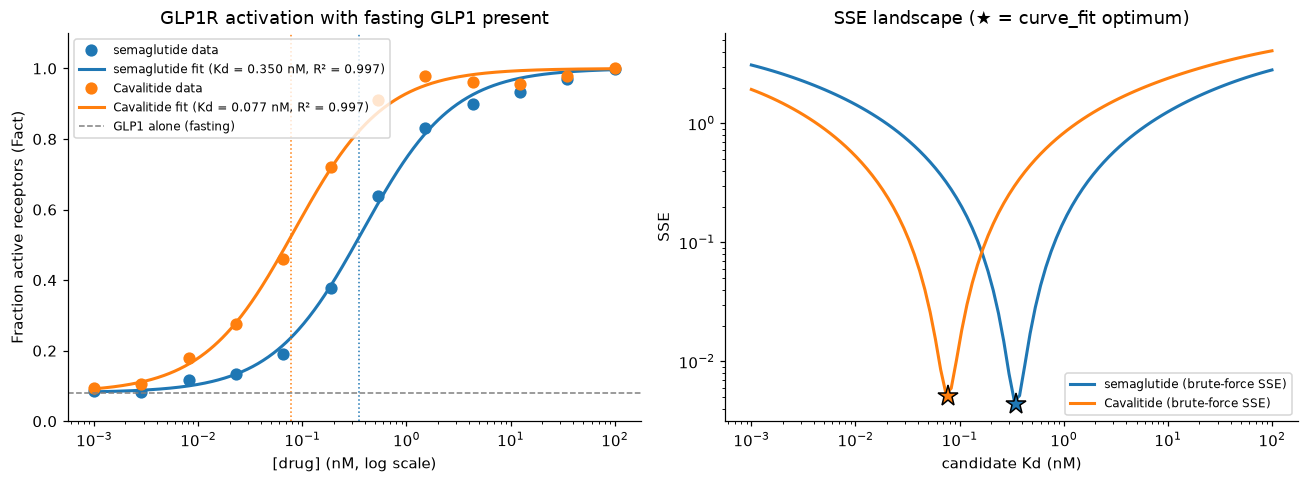

Cavalitide residuals: [ 0.003 -0.005  0.016 -0.003 -0.025  0.003  0.035  0.027 -0.022 -0.038
 -0.019  0.001]
max |residual| = 0.038


In [3]:
L2 = np.logspace(-3, 2, 500)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
colors = {"semaglutide": "tab:blue", "Cavalitide": "tab:orange"}

ax = axes[0]
for name, f in fits.items():
    c = colors[name]
    ax.semilogx(f["L2"], f["F"], "o", c=c, ms=7, label=f"{name} data")
    ax.semilogx(L2, Fact(L1_fast, L2, Kd1, f["cf"]), "-", c=c, lw=2,
                label=f"{name} fit (Kd = {f['cf']:.3f} nM, R² = {f['R2']:.3f})")
    ax.axvline(f["cf"], ls=":", c=c, lw=1)
ax.axhline(Fact(L1_fast, 0, Kd1, 1), ls="--", c="gray", lw=1, label="GLP1 alone (fasting)")
ax.set_xlabel("[drug] (nM, log scale)")
ax.set_ylabel("Fraction active receptors (Fact)")
ax.set_ylim(0, 1.1)
ax.set_title("GLP1R activation with fasting GLP1 present")
ax.legend(fontsize=8, loc="upper left")

ax = axes[1]
for name, f in fits.items():
    ax.loglog(f["cand"], f["sses"], c=colors[name], lw=2, label=f"{name} (brute-force SSE)")
    ax.plot(f["cf"], f["sse_cf"], "*", c=colors[name], ms=14, mec="k")
ax.set_xlabel("candidate Kd (nM)")
ax.set_ylabel("SSE")
ax.set_title("SSE landscape (★ = curve_fit optimum)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Residuals check: no systematic trend means the model shape fits the data
f = fits["Cavalitide"]
res = f["F"] - Fact(L1_fast, f["L2"], Kd1, f["cf"])
print("Cavalitide residuals:", np.round(res, 3))
print(f"max |residual| = {np.abs(res).max():.3f}")

### (c) Interpretation of Kd

**Cavalitide Kd ≈ 0.077 nM**, compared with ≈ 0.35 nM for semaglutide fitted the same way (literature value 0.38 nM). All three methods agree, the SSE landscape has a single clear minimum, R² > 0.99, and the residuals are small with no trend. Kd is the concentration that occupies half of the receptors, so Cavalitide binds GLP1R about **4–5× more tightly** than semaglutide. It also binds more tightly than native GLP1 (0.17 nM) and liraglutide (0.11 nM).

**Advantages**
- It needs a lower concentration to activate the same fraction of receptors. This means a lower dose or a lower required oral bioavailability, which matters most for an oral drug that is poorly absorbed.
- Receptor activation stays high even when drug concentration drops between doses (see Task 3).
- As a small molecule, it could be cheaper to make than a peptide and could be given orally.

**Disadvantages / risks**
- A lower Kd means higher potency, not higher maximal effect. Both drugs reach Fact → 1. In this model, potency only shifts the curve to the left.
- Because it binds so tightly, the curve is steep in the sub-nM range. Small differences in exposure between patients could push the receptor to near-full activation. This could worsen dose-dependent GI side effects, so careful dose titration would be needed.
- Very tight binding can drive receptor internalization and desensitization. This equilibrium model does not include either effect.
- Kd alone does not determine clinical success. Plasma protein binding, half-life, absorption and off-target effects (Tasks 2–3) matter as much. The comparison is also only valid if the assay conditions (fasting GLP1 = 0.015 nM) match how Cavalitide would actually be used.

## Task 2: Simulate the pharmacokinetics of Cavalitide treatment

### Model structure (Nov 10 lecture)
Drug enters the body through one of two depots: the **gut (g)**, for oral dosing, or **subcutaneous tissue (sc)**, for injections. From there it is absorbed into the **central (c)** compartment (plasma), with rate constant $k_g$ or $k_{sc}$. The central compartment can exchange drug with a **peripheral (p)** compartment, and drug is removed from the body by excretion at rate $k_e$.

```
         subcutaneous (sc)
                │ k_sc
  gut (g) ──k_g──▶ central (c) ◀──k_p / k_pc──▶ peripheral (p)
                │ k_e
             excretion
```

**Assumptions**
1. Each compartment is well mixed, so concentration varies with time only: $C(t) = A(t)/V$.
2. All transfers follow first-order kinetics: rate $= k \cdot A$, with $k$ in h⁻¹.
3. Each dose places $F \cdot D$ into its depot, where $F$ is the bioavailability (0–1) and $D$ is the dose in mg.
4. Only free (unbound) drug in plasma can bind GLP1R. Semaglutide is more than 99% bound to albumin [8,11], so the PD model uses $C_{free} = f_u \cdot C$.
5. Peripheral-compartment parameters are not available for either drug, so $k_p = k_{pc} = 0$ in the simulations. The compartment is kept in the code so it can be enabled once data are available.

**System of ODEs** (amounts $A$ in mg):

$$\frac{dA_g}{dt} = -k_g A_g, \qquad \frac{dA_{sc}}{dt} = -k_{sc} A_{sc}$$
$$\frac{dA_c}{dt} = k_g A_g + k_{sc} A_{sc} - k_e A_c - k_p A_c + k_{pc} A_p, \qquad \frac{dA_p}{dt} = k_p A_c - k_{pc} A_p$$

Concentration is converted from mg/L to molar units with $[M] = C\,[\text{mg/L}] / (1000 \cdot MW)$, so that $[\text{nM}] = C \cdot 10^6 / MW$.

**Numerical method: Euler's method.** For a system $d\vec{Y}/dt = \vec{f}(t, \vec{Y}, \vec{p})$, the update is $\vec{Y}_{i+1} = \vec{Y}_i + \vec{f}(t_i, \vec{Y}_i, \vec{p})\,h$, where $h$ is the step size.

### 2a. Verification: a single IV bolus of semaglutide
For a single intravenous bolus with no absorption step, the model reduces to $dC_c/dt = -k_e C_c$ with $C_c(0) = FD/V$. This equation has the analytical solution $C_c(t) = \frac{FD}{V} e^{-k_e t}$. Using the class values for semaglutide ($F$ = 0.89, $D$ = 2 mg, $V$ = 10.8 L, $k_e$ = 0.0039 h⁻¹), $C_c(0)$ = 0.165 mg/L and $t_{1/2} = \ln 2 / k_e$ ≈ 178 h. Comparing Euler's method with this exact solution checks the solver and shows how step size affects accuracy.

C(0) = FD/V = 0.165 mg/L;  t1/2 = ln2/ke = 178 h
h =   1 h: max error = 1.18e-04 mg/L (0.07% of C0)
h =  50 h: max error = 6.45e-03 mg/L (3.91% of C0)
h = 100 h: max error = 1.42e-02 mg/L (8.63% of C0)


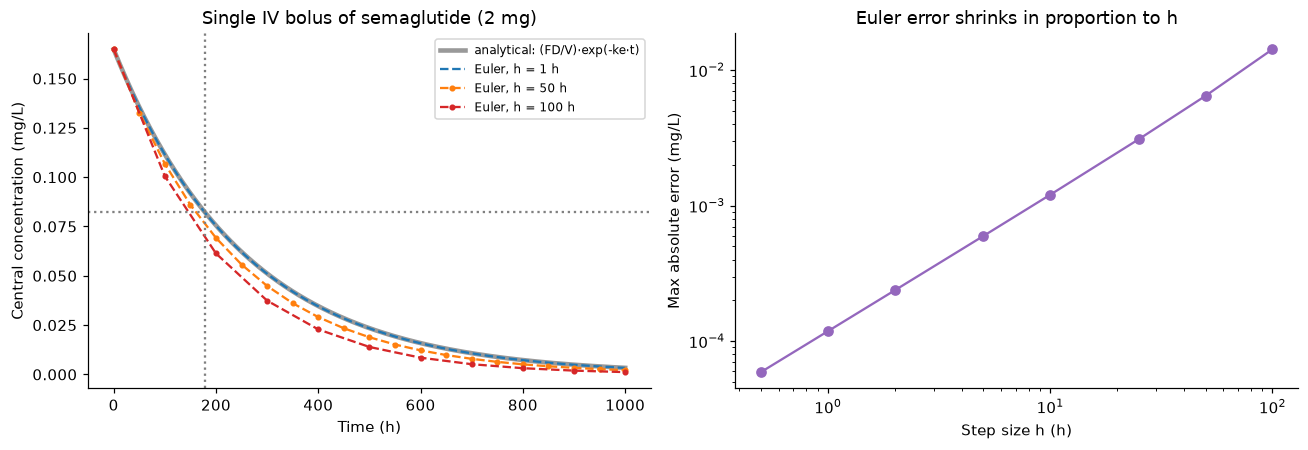

In [4]:
def euler(f, y0, t_end, h, p):
    # Euler's method for dY/dt = f(t, Y, p); returns t and Y arrays
    n = int(round(t_end / h))
    t = np.arange(n + 1) * h
    Y = np.zeros((n + 1, len(y0)))
    Y[0] = y0
    for i in range(n):
        Y[i+1] = Y[i] + f(t[i], Y[i], p) * h
    return t, Y

# Single IV bolus of semaglutide (class example)
F_s, D_s, V_s, ke_s = 0.89, 2.0, 10.8, 0.0039
C0 = F_s * D_s / V_s
print(f"C(0) = FD/V = {C0:.3f} mg/L;  t1/2 = ln2/ke = {np.log(2)/ke_s:.0f} h")

t_exact = np.linspace(0, 1000, 500)
C_exact = C0 * np.exp(-ke_s * t_exact)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(t_exact, C_exact, "k", lw=3, alpha=0.4, label="analytical: (FD/V)·exp(-ke·t)")
for h, c in [(1, "tab:blue"), (50, "tab:orange"), (100, "tab:red")]:
    t_e, Y_e = euler(lambda t, y, p: -p * y, [C0], 1000, h, ke_s)
    axes[0].plot(t_e, Y_e[:, 0], "--o" if h > 1 else "--", c=c, ms=3, lw=1.5, label=f"Euler, h = {h} h")
    err = np.max(np.abs(Y_e[:, 0] - C0*np.exp(-ke_s*t_e)))
    print(f"h = {h:>3} h: max error = {err:.2e} mg/L ({100*err/C0:.2f}% of C0)")
axes[0].axvline(178, ls=":", c="gray"); axes[0].axhline(C0/2, ls=":", c="gray")
axes[0].set_xlabel("Time (h)"); axes[0].set_ylabel("Central concentration (mg/L)")
axes[0].set_title("Single IV bolus of semaglutide (2 mg)"); axes[0].legend(fontsize=8)

hs = np.array([0.5, 1, 2, 5, 10, 25, 50, 100])
errs = [np.max(np.abs(euler(lambda t, y, p: -p*y, [C0], 1000, h, ke_s)[1][:, 0]
                      - C0*np.exp(-ke_s*euler(lambda t, y, p: -p*y, [C0], 1000, h, ke_s)[0]))) for h in hs]
axes[1].loglog(hs, errs, "o-", c="tab:purple")
axes[1].set_xlabel("Step size h (h)"); axes[1].set_ylabel("Max absolute error (mg/L)")
axes[1].set_title("Euler error shrinks in proportion to h")
plt.tight_layout(); plt.show()

Euler's method reproduces the analytical solution, and its error is proportional to the step size $h$, as expected for a first-order method. Halving $h$ halves the error. A step of $h$ = 0.1 h is used for all multiple-dose simulations below. This keeps the error negligible even for the fastest absorption rate ($k_g$ = 1 h⁻¹, where $k_g h$ = 0.1 ≪ 1).

### 2b. Repeated dosing: semaglutide vs. Cavalitide

**Parameters**

| | SC semaglutide (Ozempic) | Oral semaglutide (Rybelsus) | Oral Cavalitide (**assumed**) |
|---|---|---|---|
| Dose / interval | 2 mg / 7 d (class) | 14 mg / 1 d [8] | X mg / 1 d (chosen below) |
| Bioavailability F | 0.89 (class) | 0.008 [8] | 0.30 (assumed) |
| Absorption | $k_{sc}$ = 0.03 h⁻¹ (Tmax 1–3 d) [6] | $k_g$ = 1 h⁻¹ (Tmax ~1 h) [8] | $k_g$ = 0.8 h⁻¹ (assumed) |
| Excretion $k_e$ | 0.0039 h⁻¹, t½ ≈ 178 h (class) | 0.0039 h⁻¹ (class) | 0.023 h⁻¹, t½ = 30 h (assumed; similar to orforglipron [9]) |
| Volume V | 10.8 L (class) | 10.8 L (class) | 150 L (assumed; small molecules distribute widely) |
| Peripheral $k_p$, $k_{pc}$ | 0 (no data) | 0 (no data) | 0 (no data) |
| Free fraction $f_u$ | 0.01 (>99% albumin bound) [11] | 0.01 | 0.05 (assumed) |
| MW (g/mol) | 4113.6 | 4113.6 | 500 (assumed small molecule) |

*Cavalitide PK values are not yet available. The values above are representative of an orally administered small molecule and should be treated as working assumptions.*

In [5]:
PK = {
    "SC semaglutide (2 mg weekly)":   dict(route="sc",  dose_mg=2.0,  tau_h=168, F=0.89,  k_abs=0.03, ke=0.0039,      V=10.8, kp=0.0, kpc=0.0, fu=0.01, MW=4113.6, Kd=Kd_sema),
    "Oral semaglutide (14 mg daily)": dict(route="oral", dose_mg=14.0, tau_h=24,  F=0.008, k_abs=1.0,  ke=0.0039,      V=10.8, kp=0.0, kpc=0.0, fu=0.01, MW=4113.6, Kd=Kd_sema),
    "Oral Cavalitide (daily)":        dict(route="oral", dose_mg=None, tau_h=24,  F=0.30,  k_abs=0.8,  ke=np.log(2)/30, V=150,  kp=0.0, kpc=0.0, fu=0.05, MW=500.0,  Kd=Kd_cav),
}

def pk_rhs(t, A, p):
    # Four-compartment PK model from the Nov 10 lecture. A = [gut, sc, central, peripheral] in mg
    A_g, A_sc, A_c, A_p = A
    k_g = p["k_abs"] if p["route"] == "oral" else 0.0
    k_sc = p["k_abs"] if p["route"] == "sc" else 0.0
    return np.array([
        -k_g*A_g,
        -k_sc*A_sc,
        k_g*A_g + k_sc*A_sc - p["ke"]*A_c - p["kp"]*A_c + p["kpc"]*A_p,
        p["kp"]*A_c - p["kpc"]*A_p,
    ])

def simulate_pk(p, dose_mg=None, days=56, h=0.1, missed=()):
    # Repeated dosing solved with Euler's method.
    # Returns time [h] and total central (plasma) concentration [nM]. missed = indices of skipped doses.
    dose_mg = p["dose_mg"] if dose_mg is None else dose_mg
    n = int(round(days*24 / h))
    steps_per_dose = int(round(p["tau_h"] / h))
    depot = 0 if p["route"] == "oral" else 1
    t = np.arange(n) * h
    A = np.zeros(4)
    C = np.zeros(n)
    for i in range(n):
        if i % steps_per_dose == 0 and (i // steps_per_dose) not in missed:
            A[depot] += p["F"] * dose_mg           # A(dose) = F*D enters the depot
        C[i] = A[2] / p["V"] * 1e6 / p["MW"]       # mg/L -> nM
        A = A + pk_rhs(t[i], A, p) * h             # Euler step
    return t, C

# Check: analytical average steady-state concentration = F*D / (ke*V*tau)
p = PK["SC semaglutide (2 mg weekly)"]
t, C = simulate_pk(p, days=70)
ss = t >= 63*24
Cavg_analytic = p["F"]*p["dose_mg"] / (p["ke"]*p["V"]*p["tau_h"]) * 1e6 / p["MW"]
print(f"SC semaglutide steady-state Cavg: Euler = {C[ss].mean():.1f} nM, analytical = {Cavg_analytic:.1f} nM "
      f"(free = {p['fu']*C[ss].mean():.2f} nM)")

SC semaglutide steady-state Cavg: Euler = 61.1 nM, analytical = 61.2 nM (free = 0.61 nM)


### Choosing a Cavalitide dose
We pick the daily Cavalitide dose by **matching the steady-state free-drug receptor activation of weekly SC semaglutide**, which is the current best-in-class treatment. To do this we sweep the dose and compute the average steady-state Fact for each one, using the same PD model as Task 1.

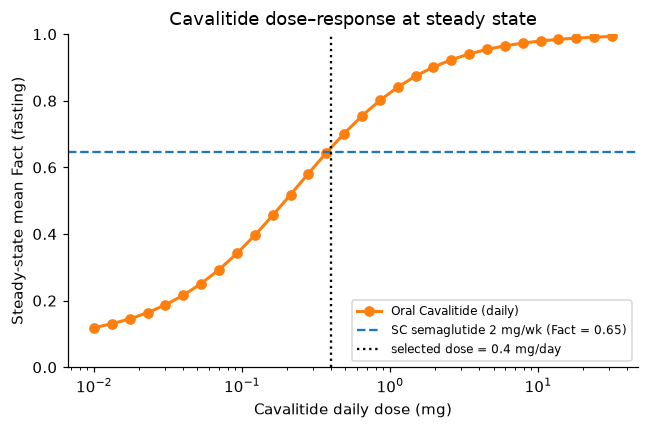

Selected Cavalitide dose: 0.4 mg once daily


In [6]:
def ss_metrics(name, dose_mg=None, L1=L1_fast, days=70):
    p = PK[name]
    t, C = simulate_pk(p, dose_mg=dose_mg, days=days)
    ss = t >= (days - 7)*24                  # last week = steady state
    Fa = Fact(L1, p["fu"]*C, Kd1, p["Kd"])
    return dict(Cavg=C[ss].mean(), Cmax=C[ss].max(), Cmin=C[ss].min(),
                Favg=Fa[ss].mean(), Fmin=Fa[ss].min(), Fmax=Fa[ss].max())

target = ss_metrics("SC semaglutide (2 mg weekly)")["Favg"]
doses = np.logspace(-2, 1.5, 30)   # 0.01 to ~30 mg
Fcav = np.array([ss_metrics("Oral Cavalitide (daily)", d)["Favg"] for d in doses])
dose_cav = float(np.interp(target, Fcav, doses))   # Fcav increases with dose
dose_cav = np.ceil(dose_cav*10)/10                # round up to the nearest 0.1 mg tablet strength
PK["Oral Cavalitide (daily)"]["dose_mg"] = dose_cav

plt.figure(figsize=(6, 4))
plt.semilogx(doses, Fcav, "o-", c="tab:orange", lw=2, label="Oral Cavalitide (daily)")
plt.axhline(target, ls="--", c="tab:blue", label=f"SC semaglutide 2 mg/wk (Fact = {target:.2f})")
plt.axvline(dose_cav, ls=":", c="k", label=f"selected dose = {dose_cav:.1f} mg/day")
plt.xlabel("Cavalitide daily dose (mg)")
plt.ylabel("Steady-state mean Fact (fasting)")
plt.title("Cavalitide dose–response at steady state")
plt.ylim(0, 1); plt.legend(fontsize=8); plt.tight_layout(); plt.show()
print(f"Selected Cavalitide dose: {dose_cav:.1f} mg once daily")

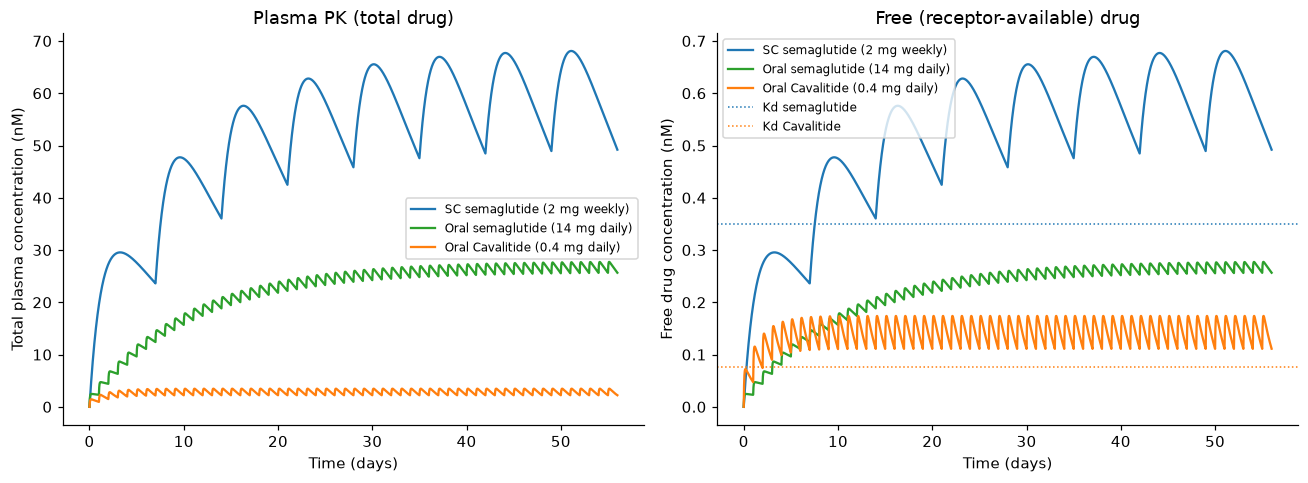

regimen                               Cavg    Cmin    Cmax  peak/trough  t to 90% SS (d)
SC semaglutide (2 mg weekly)         61.05   49.31   68.39         1.39             15.3
Oral semaglutide (14 mg daily)       26.88   25.72   27.84         1.08             21.1


Oral Cavalitide (daily)               2.89    2.22    3.48         1.57              2.1


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
pk_colors = {"SC semaglutide (2 mg weekly)": "tab:blue",
             "Oral semaglutide (14 mg daily)": "tab:green",
             "Oral Cavalitide (daily)": "tab:orange"}
sims = {}
for name, p in PK.items():
    t, C = simulate_pk(p, days=56)
    sims[name] = (t, C)
    lab = name if p["dose_mg"] is None or "Cavalitide" not in name else f"Oral Cavalitide ({p['dose_mg']:.1f} mg daily)"
    axes[0].plot(t/24, C, c=pk_colors[name], lw=1.5, label=lab)
    axes[1].plot(t/24, p["fu"]*C, c=pk_colors[name], lw=1.5, label=lab)
axes[0].set_ylabel("Total plasma concentration (nM)")
axes[0].set_title("Plasma PK (total drug)")
axes[1].set_ylabel("Free drug concentration (nM)")
axes[1].set_title("Free (receptor-available) drug")
for name, f in fits.items():
    axes[1].axhline(f["cf"], ls=":", c=colors[name], lw=1, label=f"Kd {name}")
for ax in axes:
    ax.set_xlabel("Time (days)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'regimen':<34}{'Cavg':>8}{'Cmin':>8}{'Cmax':>8}{'peak/trough':>13}{'t to 90% SS (d)':>17}")
for name, p in PK.items():
    t, C = simulate_pk(p, days=70)
    m = ss_metrics(name)
    # time to reach 90% of steady-state average concentration
    t90 = t[np.argmax(C >= 0.9*m["Cavg"])]/24
    print(f"{name:<34}{m['Cavg']:>8.2f}{m['Cmin']:>8.2f}{m['Cmax']:>8.2f}{m['Cmax']/m['Cmin']:>13.2f}{t90:>17.1f}")

**Task 2 interpretation.** Weekly SC semaglutide (2 mg) reaches a simulated steady-state average of about **61 nM** total (≈ 0.6 nM free). This matches the analytical steady-state average $FD/(k_e V \tau)$ = 61.2 nM. It is also consistent with the ≈ 75 nM reported for the 2.4 mg Wegovy dose [6], which scales to ≈ 62 nM at 2 mg. Together these checks support the model and the Euler solver. Because its half-life is about a week, both semaglutide regimens take **about 2–3 weeks** to reach 90% of steady state. Oral semaglutide needs 14 mg every day because less than 1% of it is absorbed. With the assumed parameters, **0.4 mg/day of Cavalitide** reaches 90% of steady state in **about 2 days**. It needs a much smaller daily dose than oral semaglutide because its bioavailability is higher and it binds more tightly. The trade-off is that its shorter half-life produces the largest peak-to-trough ratio of the three regimens (≈ 1.6, compared with 1.4 for weekly SC and 1.1 for oral semaglutide).

## Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment

We connect the models by feeding the **free drug concentration from Task 2** into the **receptor-binding model from Task 1**:

$$F_{act}(t) = \frac{K_{d2}L_1 + K_{d1}\,f_u C(t)}{K_{d1}K_{d2} + K_{d2}L_1 + K_{d1}\,f_u C(t)}$$

This assumes that binding reaches equilibrium quickly compared with the PK (minutes vs. hours to days). GLP1 is simulated at both fasting (0.015 nM) and fed (0.040 nM) levels.

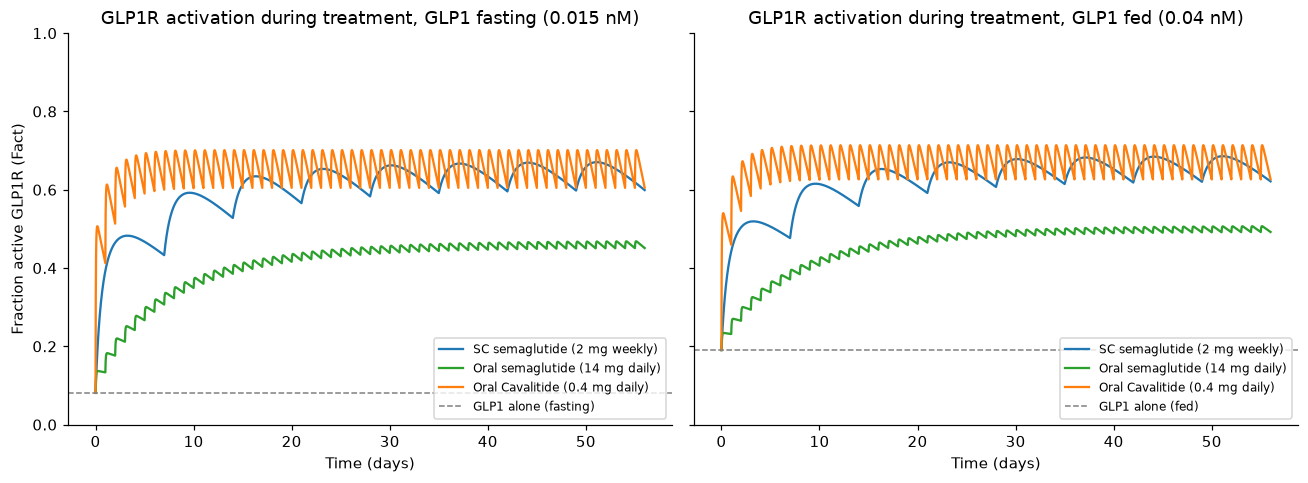

regimen (steady state, fasting)     Fact avg  Fact min  Fact max
SC semaglutide (2 mg weekly)           0.646     0.600     0.671
Oral semaglutide (14 mg daily)         0.461     0.452     0.469


Oral Cavalitide (daily)                0.660     0.605     0.701


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (state, L1) in zip(axes, [("fasting", L1_fast), ("fed", L1_fed)]):
    for name, p in PK.items():
        t, C = sims[name]
        lab = f"Oral Cavalitide ({p['dose_mg']:.1f} mg daily)" if "Cavalitide" in name else name
        ax.plot(t/24, Fact(L1, p["fu"]*C, Kd1, p["Kd"]), c=pk_colors[name], lw=1.5, label=lab)
    ax.axhline(Fact(L1, 0, Kd1, 1), ls="--", c="gray", lw=1, label=f"GLP1 alone ({state})")
    ax.set_title(f"GLP1R activation during treatment, GLP1 {state} ({L1} nM)")
    ax.set_xlabel("Time (days)")
    ax.set_ylim(0, 1)
    ax.legend(fontsize=8, loc="lower right")
axes[0].set_ylabel("Fraction active GLP1R (Fact)")
plt.tight_layout(); plt.show()

print(f"{'regimen (steady state, fasting)':<34}{'Fact avg':>10}{'Fact min':>10}{'Fact max':>10}")
for name in PK:
    m = ss_metrics(name)
    print(f"{name:<34}{m['Favg']:>10.3f}{m['Fmin']:>10.3f}{m['Fmax']:>10.3f}")

### Robustness to a missed dose
Imperfect adherence is common in chronic therapy. We simulate missing **one dose at steady state**: one weekly injection for SC semaglutide, or one daily tablet for the oral drugs. We then compare how much receptor activation drops.

regimen                             Fact min (normal)  Fact min (missed)
SC semaglutide (2 mg weekly)                    0.596              0.450


Oral semaglutide (14 mg daily)                  0.448              0.429
Oral Cavalitide (daily)                         0.605              0.478


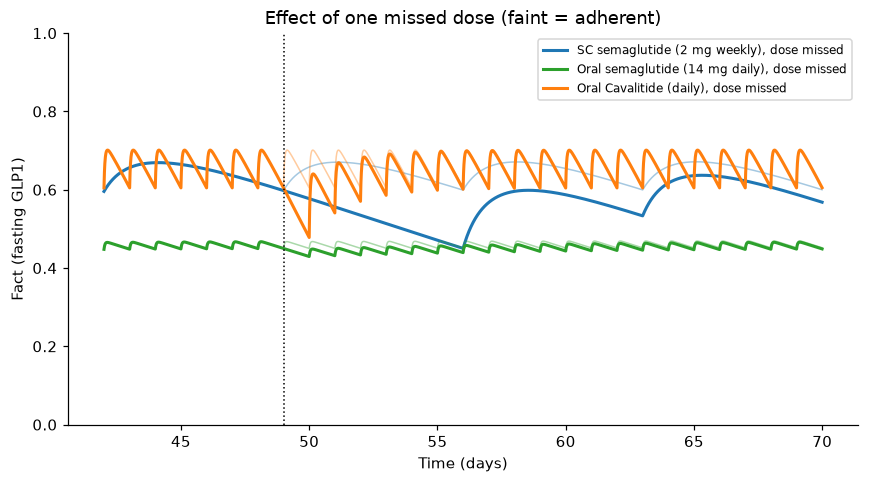

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
print(f"{'regimen':<34}{'Fact min (normal)':>19}{'Fact min (missed)':>19}")
for name, p in PK.items():
    day_missed = 49                       # day 49 = week 7, at/near steady state
    k = int(day_missed*24 / p["tau_h"])
    t, C = simulate_pk(p, days=70)
    tm, Cm = simulate_pk(p, days=70, missed=(k,))
    F_ok = Fact(L1_fast, p["fu"]*C, Kd1, p["Kd"])
    F_miss = Fact(L1_fast, p["fu"]*Cm, Kd1, p["Kd"])
    win = (t >= 42*24)
    ax.plot(t[win]/24, F_ok[win], c=pk_colors[name], lw=1, alpha=0.4)
    ax.plot(tm[win]/24, F_miss[win], c=pk_colors[name], lw=2, label=f"{name}, dose missed")
    print(f"{name:<34}{F_ok[t >= 42*24].min():>19.3f}{F_miss[t >= 42*24].min():>19.3f}")
ax.axvline(49, ls=":", c="k", lw=1)
ax.set_xlabel("Time (days)"); ax.set_ylabel("Fact (fasting GLP1)")
ax.set_title("Effect of one missed dose (faint = adherent)")
ax.set_ylim(0, 1); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### Sensitivity to the assumed Cavalitide PK parameters
Because Cavalitide's PK values are assumptions, we vary each one by 0.5× and 2×. We then check how the steady-state mean Fact changes at the selected dose. This shows which parameters are most important to measure.

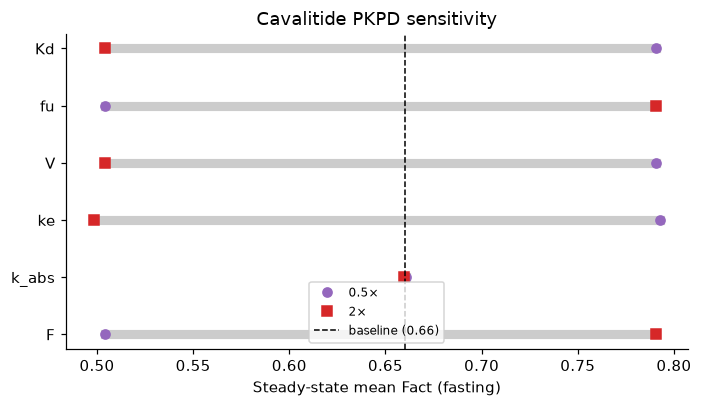

In [10]:
base = dict(PK["Oral Cavalitide (daily)"])
base_F = ss_metrics("Oral Cavalitide (daily)")["Favg"]
rows = []
for par in ["F", "k_abs", "ke", "V", "fu", "Kd"]:
    out = []
    for mult in (0.5, 2.0):
        PK["Oral Cavalitide (daily)"] = dict(base, **{par: base[par]*mult})
        out.append(ss_metrics("Oral Cavalitide (daily)")["Favg"])
    rows.append((par, *out))
PK["Oral Cavalitide (daily)"] = base

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for i, (par, lo_, hi_) in enumerate(rows):
    ax.plot([lo_, hi_], [i, i], c="gray", lw=6, alpha=0.4)
    ax.plot(lo_, i, "o", c="tab:purple", label="0.5×" if i == 0 else None)
    ax.plot(hi_, i, "s", c="tab:red", label="2×" if i == 0 else None)
ax.axvline(base_F, c="k", ls="--", lw=1, label=f"baseline ({base_F:.2f})")
ax.set_yticks(range(len(rows))); ax.set_yticklabels([r[0] for r in rows])
ax.set_xlabel("Steady-state mean Fact (fasting)")
ax.set_title("Cavalitide PKPD sensitivity")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Task 3 interpretation.** At the selected dose, Cavalitide matches the average steady-state GLP1R activation of weekly SC semaglutide, by design, and does far better than native GLP1 alone. The PKPD model shows three main differences:
1. **Onset:** Cavalitide reaches steady-state receptor activation within a few days, while semaglutide takes 2–3 weeks. In practice, semaglutide is also titrated up over 16 weeks to limit GI side effects, so a faster drug would still need its own titration plan.
2. **Fluctuation:** Cavalitide's daily dosing and shorter half-life create a daily rise and fall in Fact (≈ 0.61–0.70 at steady state, compared with 0.60–0.67 for weekly SC semaglutide). The binding curve flattens as receptors saturate, so Fact swings proportionally less than concentration does.
3. **Missed doses:** missing one weekly semaglutide injection lowers the minimum Fact from ≈ 0.60 to ≈ 0.45, because a full week of drug is lost. Missing one daily Cavalitide tablet lowers it from ≈ 0.61 to ≈ 0.48, and activation recovers within about a day of the next tablet. Oral semaglutide is the most forgiving (≈ 0.45 → 0.43) because each daily dose is a small fraction of its long-half-life body stores. The trade-off is that daily pills give more chances to miss a dose than a weekly injection.

The sensitivity analysis shows that the result depends most on **bioavailability (F), free fraction (fu), clearance (V and half-life) and Kd**. These are the first things to measure in preclinical and Phase 1 studies.

## Conclusions:

- **Pharmacodynamics:** Cavalitide is a **≈ 4.5× more potent** GLP1R agonist than semaglutide (Kd ≈ 0.077 vs. 0.35 nM; data fit with R² > 0.99). In this model, both drugs reach the same maximal activation.
- **vs. oral semaglutide (Rybelsus):** this is Cavalitide's strongest competitive position. With the assumed parameters, a **0.4 mg daily tablet** reaches receptor activation similar to injected semaglutide (mean Fact ≈ 0.66 vs. 0.65), while oral semaglutide reaches only ≈ 0.46. Oral semaglutide needs 14 mg per day, ~1% bioavailability and a strict fasting routine. A small molecule could also be cheaper to make and easier to scale up.
- **vs. injected semaglutide (Wegovy/Ozempic):** Cavalitide could match average receptor activation without needles and reach steady state much faster. A single missed tablet costs less activation than a single missed injection, but patients must take it every day, and its activation fluctuates more within each dosing interval.
- **Overall:** Cavalitide looks promising as an **oral** competitor, *provided* that its real bioavailability, half-life and protein binding are close to our assumptions. Measuring these PK properties is the main development risk.

## Limitations and Future Work:

**Limitations**
- **Equilibrium binding:** the model ignores binding/unbinding kinetics, receptor internalization, desensitization and downstream signaling (cAMP → insulin, appetite). It predicts receptor activation, not weight loss.
- **Full agonist assumption:** we assumed any bound receptor is fully active. Cavalitide could be a partial or biased agonist.
- **Single binding dataset:** the fit uses one curve at fasting GLP1, with no replicates, so we cannot estimate experimental variability. Native GLP1 is held constant even though it changes with meals.
- **PK assumptions:** Cavalitide's PK parameters are placeholders. The peripheral compartment is included in the model structure but switched off ($k_p = k_{pc} = 0$) because no distribution data were available. The model also ignores brain penetration, food effects on absorption and variability between patients.
- **Numerical method:** Euler's method is first-order accurate. The step size (0.1 h) was chosen after comparing against the analytical IV-bolus solution, but a higher-order solver (e.g. `scipy.integrate.solve_ivp`) would be more efficient for larger models.
- **Free-drug hypothesis:** we assumed only unbound drug activates receptors. Albumin binding could be different at tissue receptor sites.

**Future work**
- Fit Kd from replicate data and at fed GLP1 levels, and use bootstrapping to get confidence intervals.
- Measure Cavalitide's oral bioavailability, half-life and plasma protein binding, then refit the PK model to Phase 1 concentration–time data.
- Add a population model (random variation in F, CL and V between patients) to predict the range of patient responses and choose a titration schedule.
- Link Fact to a weight-loss model fitted to STEP trial data, so different drugs can be compared on clinical outcomes.
- Test longer-acting formulations, or a GLP1R/GIPR dual agonist like tirzepatide.

## AI Usage Statement:
We used Claude Code (Anthropic) to help draft this notebook. It adapted `fit_semaglutide_GLP1R.py` into a reusable fitting function, added the hybrid brute-force/curve_fit fit and residual check, and drafted the PK/PKPD simulation code (an Euler's-method implementation of the four-compartment model from the Nov 10 lecture) and markdown text. We checked the fitted Kd against our own run of the class script, verified the Euler solver against the analytical IV-bolus solution and the analytical steady-state average, and reviewed all citations. Because the official Task 2/3 instructions were not yet released, the Cavalitide PK parameters are assumptions that we need to replace or justify.

## GitHub Repository Link:


## References:
1. Emmerich SD, Fryar CD, Stierman B, Ogden CL. *Obesity and Severe Obesity Prevalence in Adults: United States, August 2021–August 2023.* NCHS Data Brief No. 508, 2024. https://www.cdc.gov/nchs/products/databriefs/db508.htm
2. World Health Organization. *Obesity and overweight* fact sheet, 2024/2025. https://www.who.int/news-room/fact-sheets/detail/obesity-and-overweight
3. Seino Y, Fukushima M, Yabe D. GIP and GLP-1, the two incretin hormones: similarities and differences. *J Diabetes Investig.* 2010;1(1-2):8–23. (Lecture 1)
4. Müller TD et al. / Tschöp MH et al. incretin pharmacology reviews, *Diabetologia* 2023. https://pubmed.ncbi.nlm.nih.gov/37209227/ (Lecture 1)
5. Wilding JPH et al. Once-weekly semaglutide in adults with overweight or obesity (STEP 1). *N Engl J Med.* 2021;384:989–1002.
6. Novo Nordisk. WEGOVY (semaglutide) injection, U.S. Prescribing Information (Clinical Pharmacology §12.3).
7. Wilding JPH et al. Weight regain and cardiometabolic effects after withdrawal of semaglutide: the STEP 1 trial extension. *Diabetes Obes Metab.* 2022;24:1553–1564.
8. Novo Nordisk. RYBELSUS (oral semaglutide) tablets, U.S. Prescribing Information (Dosage & Administration; Clinical Pharmacology §12.3).
9. Wharton S et al. Orforglipron, an oral small-molecule GLP-1 receptor agonist, in adults with obesity. *N Engl J Med.* 2025 (ATTAIN-1); and Pratt E et al. orforglipron Phase 1 PK, *Diabetes Obes Metab.* 2023.
10. Lau J et al. Discovery of the once-weekly GLP-1 analogue semaglutide. *J Med Chem.* 2015;58(18):7370–7380. (Kd values, Lecture 2)
11. Hall S et al. Pharmacokinetics of semaglutide (clinical pharmacology review). *Clin Pharmacokinet.* 2018 / Overgaard RV et al. 2021.
12. BME 2315 Module 3 Lectures 1–3 (J. Saucerman, 2026) and course code: `ligand_receptor.py`, `GLP1_GLP1R.py`, `fit_semaglutide_GLP1R.py`.

## Team Notes:
- Task 1 complete: Cavalitide Kd ≈ 0.077 nM; semaglutide refit ≈ 0.35 nM (vs. 0.38 nM literature).
- Tasks 2/3 drafted with assumed Cavalitide PK parameters. **Update the `PK` table after the 11/10 and 11/12 lectures.**
- TODO: add team names, GitHub link, confirm references, finalize slides for the 11/17 presentation.

## Questions for the TA:
1. Will we be given specific PK parameters (bioavailability, half-life, Vd, protein binding) for Cavalitide, or should we justify our own assumptions?
2. Should the PKPD model use free (unbound) or total plasma drug concentration as the input to the receptor model?
3. Should Cavalitide be modeled as oral only, or compared against both oral and injected semaglutide?